In [2]:
## Identificación de Z1 y Z2, montando la señal MC Higgs, MC ZZ 4e y los datos Run2012B y RUn 2012C (para electrones), para el canal 4e
# ademas de aplixar delta R, Parámetro impacto dxy<0.5, dz<1.0 y una luminosidad de 11.46 fb inversos en archvios parquet de las columans con electrones >= 4

In [3]:
import awkward as ak
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import mplhep as hep

In [4]:
df_4el = pd.read_parquet("df_data_4el.parquet")
df_4el_higgs = pd.read_parquet("df_higgs_4el.parquet")
df_4el_zz = pd.read_parquet("df_zz_4el.parquet")

print("Número de eventos con 4 electrones listos para procesar:", len(df_4el))
print("Número de eventos con 4 electrones (Higgs MC):", len(df_4el_higgs))
print("Número de eventos con 4 electrones (ZZ MC):", len(df_4el_zz))

Número de eventos con 4 electrones listos para procesar: 46
Número de eventos con 4 electrones (Higgs MC): 6006
Número de eventos con 4 electrones (ZZ MC): 59246


In [5]:
# Ver las columnas de tus DataFrames de muones
print("Columnas en df_4mu:", df_4el.columns.tolist())
print("Columnas en df_4mu_higgs:", df_4el_higgs.columns.tolist())
print("Columnas en df_4mu_zz:", df_4el_zz.columns.tolist())

Columnas en df_4mu: ['run', 'luminosityBlock', 'event', 'pt1', 'eta1', 'phi1', 'charge1', 'iso1', 'dxy1', 'dz1', 'dxyErr1', 'dzErr1', 'pt2', 'eta2', 'phi2', 'charge2', 'iso2', 'dxy2', 'dz2', 'dxyErr2', 'dzErr2', 'pt3', 'eta3', 'phi3', 'charge3', 'iso3', 'dxy3', 'dz3', 'dxyErr3', 'dzErr3', 'pt4', 'eta4', 'phi4', 'charge4', 'iso4', 'dxy4', 'dz4', 'dxyErr4', 'dzErr4', 'sip3d1', 'sip3d2', 'sip3d3', 'sip3d4', 'mZ1', 'mZ2', 'Z1_idx_a', 'Z1_idx_b', 'Z2_idx_c', 'Z2_idx_d', 'M']
Columnas en df_4mu_higgs: ['run', 'luminosityBlock', 'event', 'pt1', 'eta1', 'phi1', 'charge1', 'iso1', 'dxy1', 'dz1', 'dxyErr1', 'dzErr1', 'pt2', 'eta2', 'phi2', 'charge2', 'iso2', 'dxy2', 'dz2', 'dxyErr2', 'dzErr2', 'pt3', 'eta3', 'phi3', 'charge3', 'iso3', 'dxy3', 'dz3', 'dxyErr3', 'dzErr3', 'pt4', 'eta4', 'phi4', 'charge4', 'iso4', 'dxy4', 'dz4', 'dxyErr4', 'dzErr4', 'sip3d1', 'sip3d2', 'sip3d3', 'sip3d4', 'mZ1', 'mZ2', 'Z1_idx_a', 'Z1_idx_b', 'Z2_idx_c', 'Z2_idx_d', 'M']
Columnas en df_4mu_zz: ['run', 'luminosityBl

In [6]:
# Quitamos valores negativos como los valores centinela ( -999) de las columnas de iso1, iso2, iso3, iso4

def solo_positivos(df): 
    mask_positivo = (df["iso1"] >= 0) & (df["iso2"] >= 0) & (df["iso3"] >= 0) & (df["iso4"] >= 0)
    return df[mask_positivo].copy()

# Aplicamos y guardamos el filtro de forma independiente para cada DataFrame
df_4el  = solo_positivos(df_4el)
df_4el_higgs = solo_positivos(df_4el_higgs)
df_4el_zz    = solo_positivos(df_4el_zz)

# Verificación final de los conteos limpios
print("Datos reales listos (sin -999):", len(df_4el))
print("Higgs MC listo (sin -999):     ", len(df_4el_higgs))
print("ZZ MC listo (sin -999):        ", len(df_4el_zz))


Datos reales listos (sin -999): 46
Higgs MC listo (sin -999):      6006
ZZ MC listo (sin -999):         59246


In [7]:
# Comprobar si son el mismo objeto en memoria
print("¿Son el mismo DataFrame en memoria?", df_4el is df_4el_higgs)
# Verificamos los valores mínimos de aislamiento en los datos limpios
print("Mínimos de aislamiento (Datos):\n", df_4el[["iso1", "iso2", "iso3", "iso4"]].min())

¿Son el mismo DataFrame en memoria? False
Mínimos de aislamiento (Datos):
 iso1    0.000000
iso2    0.014462
iso3    0.008591
iso4    0.009709
dtype: float32


In [11]:
# Tabla de Flujo de Cortes para 4 electrones 
# Calcular sip3d solo para los 4 electrones
for i in range(1, 5):
    ip3d = np.sqrt(df_4el[f"dxy{i}"] ** 2 + df_4el[f"dz{i}"] ** 2)
    sig = np.sqrt(df_4el[f"dxyErr{i}"] ** 2 + df_4el[f"dzErr{i}"] ** 2)
    df_4el [f"sip3d{i}"] = ip3d / sig

# Definición de máscaras para 4 electrones

mask_pt = (df_4el["pt1"] > 7) & (df_4el["pt2"] > 7) & (df_4el["pt3"] > 7) & (df_4el["pt4"] > 7)
mask_eta = mask_pt & (df_4el["eta1"].abs() < 2.5) & (df_4el["eta2"].abs() < 2.5) & (df_4el["eta3"].abs() < 2.5) & (df_4el["eta4"].abs() < 2.5)
mask_iso = mask_eta & (df_4el["iso1"] < 0.40) & (df_4el["iso2"] < 0.40) & (df_4el["iso3"] < 0.40) & (df_4el["iso4"] < 0.40)
mask_sip = mask_iso & (df_4el["sip3d1"] < 4) & (df_4el["sip3d2"] < 4) & (df_4el["sip3d3"] < 4) & (df_4el["sip3d4"] < 4)
mask_dxy = mask_sip & (df_4el["dxy1"].abs() < 0.5) & (df_4el["dxy2"].abs() < 0.5) & (df_4el["dxy3"].abs() < 0.5) & (df_4el["dxy4"].abs() < 0.5)
mask_dz  = mask_dxy & (df_4el["dz1"].abs() < 1.0)  & (df_4el["dz2"].abs() < 1.0)  & (df_4el["dz3"].abs() < 1.0)  & (df_4el["dz4"].abs() < 1.0)

# DataFrame final usando filtro sip3d + dxy/dz

df_final = df_4el[mask_pt & mask_eta & mask_iso & mask_sip & mask_dxy & mask_dz].copy()

n_total = len(df_4el)
n_pt  = len(df_4el[mask_pt])
n_eta = len(df_4el[mask_eta])
n_iso = len(df_4el[mask_iso])
n_sip = len(df_4el[mask_sip]) 
n_dxy_dz = len(df_4el[mask_dz])

Tabla_flujo = {
    "Corte aplicado": [
        "Sin filtros (4 electrones)",
        "pT Líderes (> 7 GeV)",
        "Aceptancia Detector (|eta| < 2.5)",
        "Aislamiento iso < 0.40",
        "Parámetro impacto sip3d < 4",
        "Parámetro impacto dxy<0.5, dz<1.0 (Final)",
    ],
    "Eventos Restantes": [n_total, n_pt, n_eta, n_iso, n_sip, n_dxy_dz],
    "Aceptancia (%)": [
        100.0,
        (n_pt / n_total) * 100,
        (n_eta / n_total) * 100,
        (n_iso / n_total) * 100,
        (n_sip / n_total) * 100,
        (n_dxy_dz / n_total) * 100,
    ],
}
tabla_flujo = pd.DataFrame(Tabla_flujo)
print("\nTabla de Flujo de Cortes (Canal H -> ZZ* -> 4e)")
print(tabla_flujo)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

#  Higgs MC (df_4el_higgs) 
for i in range(1, 5):
    ip3d_h = np.sqrt(df_4el_higgs[f"dxy{i}"] ** 2 + df_4el_higgs[f"dz{i}"] ** 2)
    sig_h = np.sqrt(df_4el_higgs[f"dxyErr{i}"] ** 2 + df_4el_higgs[f"dzErr{i}"] ** 2)
    df_4el_higgs[f"sip3d{i}"] = ip3d_h / sig_h
mask_pt_h = (df_4el_higgs["pt1"] > 7) & (df_4el_higgs["pt2"] > 7) & (df_4el_higgs["pt3"] > 7) & (df_4el_higgs["pt4"] > 7)
mask_eta_h = mask_pt_h & (df_4el_higgs["eta1"].abs() < 2.5) & (df_4el_higgs["eta2"].abs() < 2.5) & (df_4el_higgs["eta3"].abs() < 2.5) & (df_4el_higgs["eta4"].abs() < 2.5)
mask_iso_h = mask_eta_h & (df_4el_higgs["iso1"] < 0.40) & (df_4el_higgs["iso2"] < 0.40) & (df_4el_higgs["iso3"] < 0.40) & (df_4el_higgs["iso4"] < 0.40)
mask_sip_h = mask_iso_h & (df_4el_higgs["sip3d1"] < 4) & (df_4el_higgs["sip3d2"] < 4) & (df_4el_higgs["sip3d3"] < 4) & (df_4el_higgs["sip3d4"] < 4)
mask_dxy_h = mask_sip_h & (df_4el_higgs["dxy1"].abs() < 0.5) & (df_4el_higgs["dxy2"].abs() < 0.5) & (df_4el_higgs["dxy3"].abs() < 0.5) & (df_4el_higgs["dxy4"].abs() < 0.5)
mask_dz_h  = mask_dxy_h & (df_4el_higgs["dz1"].abs() < 1.0)  & (df_4el_higgs["dz2"].abs() < 1.0)  & (df_4el_higgs["dz3"].abs() < 1.0)  & (df_4el_higgs["dz4"].abs() < 1.0)
df_final_higgs = df_4el_higgs[mask_pt_h & mask_eta_h & mask_iso_h & mask_sip_h & mask_dxy_h & mask_dz_h].copy()

n_total_h = len(df_4el_higgs)
n_pt_h = len(df_4el_higgs[mask_pt_h])
n_eta_h = len(df_4el_higgs[mask_eta_h])
n_iso_h = len(df_4el_higgs[mask_iso_h])
n_sip_h = len(df_4el_higgs[mask_sip_h])
n_dxy_dz_h = len(df_4el_higgs[mask_dz_h])

Tabla_flujo_h = {
    "Corte aplicado": [
        "Sin filtros (Higgs MC)",
        "pT Líderes (> 7 GeV)",
        "Aceptancia Detector (|eta| < 2.5)",
        "Aislamiento iso < 0.40",
        "Parámetro impacto sip3d < 4",
        "Parámetro impacto dxy<0.5, dz<1.0 (Final)",
    ],
    "Eventos Restantes": [
        n_total_h,
        n_pt_h,
        n_eta_h,
        n_iso_h,
        n_sip_h,
        n_dxy_dz_h,
    ],
    "Aceptancia (%)": [
        100.0,
        (n_pt_h / n_total_h) * 100 if n_total_h > 0 else 0,
        (n_eta_h / n_total_h) * 100 if n_total_h > 0 else 0,
        (n_iso_h / n_total_h) * 100 if n_total_h > 0 else 0,
        (n_sip_h / n_total_h) * 100 if n_total_h > 0 else 0,
        (n_dxy_dz_h / n_total_h) * 100 if n_total_h > 0 else 0,
    ],
}
tabla_flujo_h = pd.DataFrame(Tabla_flujo_h)
print("\nTabla de Flujo de Cortes (Canal H -> ZZ* -> 4e - Higgs MC)")
print(tabla_flujo_h)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)


# Fondo ZZ MC (df_4el_zz)
for i in range(1, 5):
    ip3d_zz = np.sqrt(df_4el_zz[f"dxy{i}"] ** 2 + df_4el_zz[f"dz{i}"] ** 2)
    sig_zz = np.sqrt(df_4el_zz[f"dxyErr{i}"] ** 2 + df_4el_zz[f"dzErr{i}"] ** 2)
    df_4el_zz[f"sip3d{i}"] = ip3d_zz / sig_zz
mask_pt_zz = (df_4el_zz["pt1"] > 7) & (df_4el_zz["pt2"] > 7) & (df_4el_zz["pt3"] > 7) & (df_4el_zz["pt4"] > 7)
mask_eta_zz = mask_pt_zz & (df_4el_zz["eta1"].abs() < 2.5) & (df_4el_zz["eta2"].abs() < 2.5) & (df_4el_zz["eta3"].abs() < 2.5) & (df_4el_zz["eta4"].abs() < 2.5)
mask_iso_zz = mask_eta_zz & (df_4el_zz["iso1"] < 0.40) & (df_4el_zz["iso2"] < 0.40) & (df_4el_zz["iso3"] < 0.40) & (df_4el_zz["iso4"] < 0.40)
mask_sip_zz = mask_iso_zz & (df_4el_zz["sip3d1"] < 4) & (df_4el_zz["sip3d2"] < 4) & (df_4el_zz["sip3d3"] < 4) & (df_4el_zz["sip3d4"] < 4)
mask_dxy_zz = mask_sip_zz & (df_4el_zz["dxy1"].abs() < 0.5) & (df_4el_zz["dxy2"].abs() < 0.5) & (df_4el_zz["dxy3"].abs() < 0.5) & (df_4el_zz["dxy4"].abs() < 0.5)
mask_dz_zz  = mask_dxy_zz & (df_4el_zz["dz1"].abs() < 1.0)  & (df_4el_zz["dz2"].abs() < 1.0)  & (df_4el_zz["dz3"].abs() < 1.0)  & (df_4el_zz["dz4"].abs() < 1.0)

df_final_zz = df_4el_zz[mask_pt_zz & mask_eta_zz & mask_iso_zz & mask_sip_zz & mask_dxy_zz & mask_dz_zz].copy()

n_total_zz = len(df_4el_zz)
n_pt_zz = len(df_4el_zz[mask_pt_zz])
n_eta_zz = len(df_4el_zz[mask_eta_zz])
n_iso_zz = len(df_4el_zz[mask_iso_zz])
n_sip_zz = len(df_4el_zz[mask_sip_zz])
n_dxy_dz_zz = len(df_4el_zz[mask_dz_zz])

Tabla_flujo_zz = {
    "Corte aplicado": [
        "Sin filtros (Fondo ZZ MC)",
        "pT Líderes (> 7 GeV)",
        "Aceptancia Detector (|eta| < 2.5)",
        "Aislamiento iso < 0.40",
        "Parámetro impacto sip3d < 4",
        "Parámetro impacto dxy<0.5, dz<1.0 (Final)",
    ],
    "Eventos Restantes": [
        n_total_zz,
        n_pt_zz,
        n_eta_zz,
        n_iso_zz,
        n_sip_zz,
        n_dxy_dz_zz,
    ],
    "Aceptancia (%)": [
        100.0,
        (n_pt_zz / n_total_zz) * 100 if n_total_zz > 0 else 0,
        (n_eta_zz / n_total_zz) * 100 if n_total_zz > 0 else 0,
        (n_iso_zz / n_total_zz) * 100 if n_total_zz > 0 else 0,
        (n_sip_zz / n_total_zz) * 100 if n_total_zz > 0 else 0,
        (n_dxy_dz_zz / n_total_zz) * 100 if n_total_zz > 0 else 0,
    ],
}
tabla_flujo_zz = pd.DataFrame(Tabla_flujo_zz)
print("\nTabla de Flujo de Cortes (Canal H -> ZZ* -> 4e - Fondo ZZ MC)")
print(tabla_flujo_zz)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)




Tabla de Flujo de Cortes (Canal H -> ZZ* -> 4e)
                              Corte aplicado  Eventos Restantes  Aceptancia (%)
0                 Sin filtros (4 electrones)                 46           100.0
1                       pT Líderes (> 7 GeV)                 46           100.0
2          Aceptancia Detector (|eta| < 2.5)                 46           100.0
3                     Aislamiento iso < 0.40                 46           100.0
4                Parámetro impacto sip3d < 4                 46           100.0
5  Parámetro impacto dxy<0.5, dz<1.0 (Final)                 46           100.0

Tabla de Flujo de Cortes (Canal H -> ZZ* -> 4e - Higgs MC)
                              Corte aplicado  Eventos Restantes  Aceptancia (%)
0                     Sin filtros (Higgs MC)               6006           100.0
1                       pT Líderes (> 7 GeV)               6006           100.0
2          Aceptancia Detector (|eta| < 2.5)               6006           100.0
3          

In [7]:
# Constantes físicas para electrones (masa en GeV)
M_Electron = 0.000511
Z_Mass_Nominal = 91.1876


# Función para masa de un par de electrones

def delta_r(eta1, phi1, eta2, phi2):
    d_eta = eta1 - eta2
    d_phi = np.arctan2(np.sin(phi1 - phi2), np.cos(phi1 - phi2))
    return np.sqrt(d_eta**2 + d_phi**2)

def masa_par(df, i, j):
    px = df[f"pt{i}"] * np.cos(df[f"phi{i}"]) + df[f"pt{j}"] * np.cos(df[f"phi{j}"])
    py = df[f"pt{i}"] * np.sin(df[f"phi{i}"]) + df[f"pt{j}"] * np.sin(df[f"phi{j}"])
    pz = df[f"pt{i}"] * np.sinh(df[f"eta{i}"]) + df[f"pt{j}"] * np.sinh(df[f"eta{j}"])
    E = np.sqrt(
        df[f"pt{i}"] ** 2 + df[f"pt{i}"] ** 2 * np.sinh(df[f"eta{i}"]) ** 2 + M_Electron**2
    ) + np.sqrt(
        df[f"pt{j}"] ** 2 + df[f"pt{j}"] ** 2 * np.sinh(df[f"eta{j}"]) ** 2 + M_Electron**2
    )
    return np.sqrt(np.maximum(0.0, E**2 - (px**2 + py**2 + pz**2)))


# Identificación directa de Z1 y Z2
def identificar_Z_onoff(df):

    pares = [((1, 2), (3, 4)), ((1, 3), (2, 4)), ((1, 4), (2, 3))] # Las 3 combinaciones posibles de pares con 4 partículas

    mejor_mZ1 = np.full(len(df), np.nan)
    mejor_mZ2 = np.full(len(df), np.nan)
    mejor_diff = np.full(len(df), np.inf)
    mejor_dr_valido = np.full(len(df), False)

    mejor_idx_a = np.zeros(len(df), dtype=int)
    mejor_idx_b = np.zeros(len(df), dtype=int)
    mejor_idx_c = np.zeros(len(df), dtype=int)
    mejor_idx_d = np.zeros(len(df), dtype=int)

    for (a, b), (c, d) in pares:
        valido = (df[f"charge{a}"] + df[f"charge{b}"] == 0) & (df[f"charge{c}"] + df[f"charge{d}"] == 0)

        # ΔR de este par específico (se guarda, todavía no se usa para elegir)
        dr_ab = delta_r(df[f"eta{a}"], df[f"phi{a}"], df[f"eta{b}"], df[f"phi{b}"])
        dr_cd = delta_r(df[f"eta{c}"], df[f"phi{c}"], df[f"eta{d}"], df[f"phi{d}"])
        dr_par = (dr_ab > 0.02) & (dr_cd > 0.02)

        m_ab, m_cd = masa_par(df, a, b), masa_par(df, c, d)

        ab_es_z1 = np.abs(m_ab - Z_Mass_Nominal) < np.abs(m_cd - Z_Mass_Nominal)
        m1 = np.where(ab_es_z1, m_ab, m_cd)
        m2 = np.where(ab_es_z1, m_cd, m_ab)
        idx_a = np.where(ab_es_z1, a, c)
        idx_b = np.where(ab_es_z1, b, d)
        idx_c = np.where(ab_es_z1, c, a)
        idx_d = np.where(ab_es_z1, d, b)

        # Elección de "mejor" combinación (masa/carga)
         
        diff = np.abs(m1 - Z_Mass_Nominal)
        mask = valido & (diff < mejor_diff)
        mejor_mZ1, mejor_mZ2, mejor_diff = (
            np.where(mask, m1, mejor_mZ1),
            np.where(mask, m2, mejor_mZ2),
            np.where(mask, diff, mejor_diff),
        )
        # Se guarda el ΔR de la combinación que ganó 

        mejor_dr_valido = np.where(mask, dr_par, mejor_dr_valido)
        mejor_idx_a = np.where(mask, idx_a, mejor_idx_a)
        mejor_idx_b = np.where(mask, idx_b, mejor_idx_b)
        mejor_idx_c = np.where(mask, idx_c, mejor_idx_c)
        mejor_idx_d = np.where(mask, idx_d, mejor_idx_d)

        # Ahora (después de elegir), se aplica el ΔR como filtro final
        
    valido_final = ~np.isnan(mejor_mZ1) & mejor_dr_valido

    df["mZ1"] = np.where(valido_final, mejor_mZ1, np.nan)
    df["mZ2"] = np.where(valido_final, mejor_mZ2, np.nan)
    df["Z1_idx_a"], df["Z1_idx_b"] = mejor_idx_a, mejor_idx_b
    df["Z2_idx_c"], df["Z2_idx_d"] = mejor_idx_c, mejor_idx_d
    return df


# Datoa Reales

df_final_el = identificar_Z_onoff(df_final)
print("Eventos con mZ1 = NaN (invalidados por ΔR):", df_final_el["mZ1"].isna().sum())
print(df_final_el[["mZ1", "mZ2"]].describe())

# Aplicar los cortes de masa del skim
df_final_el = df_final_el[
    (df_final_el["mZ1"] > 40) & (df_final_el["mZ1"] < 120) &
    (df_final_el["mZ2"] > 12) & (df_final_el["mZ2"] < 120)
].copy()

print("Eventos después del skim de masa (Datos):", len(df_final_el))

# HIGGS MC 
df_final_higgs_el = identificar_Z_onoff(df_final_higgs)
print("\nHiggs MC:")
print("Eventos con mZ1 = NaN (invalidados por ΔR):", df_final_higgs_el["mZ1"].isna().sum())
print(df_final_higgs_el[["mZ1", "mZ2"]].describe())

df_final_higgs_el = df_final_higgs_el[
    (df_final_higgs_el["mZ1"] > 40) & (df_final_higgs_el["mZ1"] < 120) &
    (df_final_higgs_el["mZ2"] > 12) & (df_final_higgs_el["mZ2"] < 120)
].copy()
print("Eventos después del skim de masa (Higgs):", len(df_final_higgs_el))

# ZZ MC 
df_final_zz_el = identificar_Z_onoff(df_final_zz)
print("\nZZ MC:")
print("Eventos con mZ1 = NaN (invalidados por ΔR):", df_final_zz_el["mZ1"].isna().sum())
print(df_final_zz_el[["mZ1", "mZ2"]].describe())

df_final_zz_el = df_final_zz_el[
    (df_final_zz_el["mZ1"] > 40) & (df_final_zz_el["mZ1"] < 120) &
    (df_final_zz_el["mZ2"] > 12) & (df_final_zz_el["mZ2"] < 120)
].copy()
print("Eventos después del skim de masa (ZZ):", len(df_final_zz_el))

Eventos con mZ1 = NaN (invalidados por ΔR): 12
              mZ1         mZ2
count   82.000000   82.000000
mean    79.711083   43.627183
std     20.384464   45.331156
min      9.188709    0.184216
25%     65.327831    3.623398
50%     88.890011   25.020243
75%     92.177713   86.258911
max    171.682373  224.935562
Eventos después del skim de masa (Datos): 46

Higgs MC:
Eventos con mZ1 = NaN (invalidados por ΔR): 122
               mZ1          mZ2
count  6516.000000  6516.000000
mean     81.791031    28.606624
std      12.134283    11.712523
min      24.214788     1.220527
25%      73.978849    20.960002
50%      86.352772    28.065640
75%      90.979568    34.854198
max     111.790573   137.308044
Eventos después del skim de masa (Higgs): 6006

ZZ MC:
Eventos con mZ1 = NaN (invalidados por ΔR): 2253
                mZ1           mZ2
count  76524.000000  76524.000000
mean      81.868121     63.266400
std       16.419828     47.438737
min        7.357633      1.024838
25%       71.6643

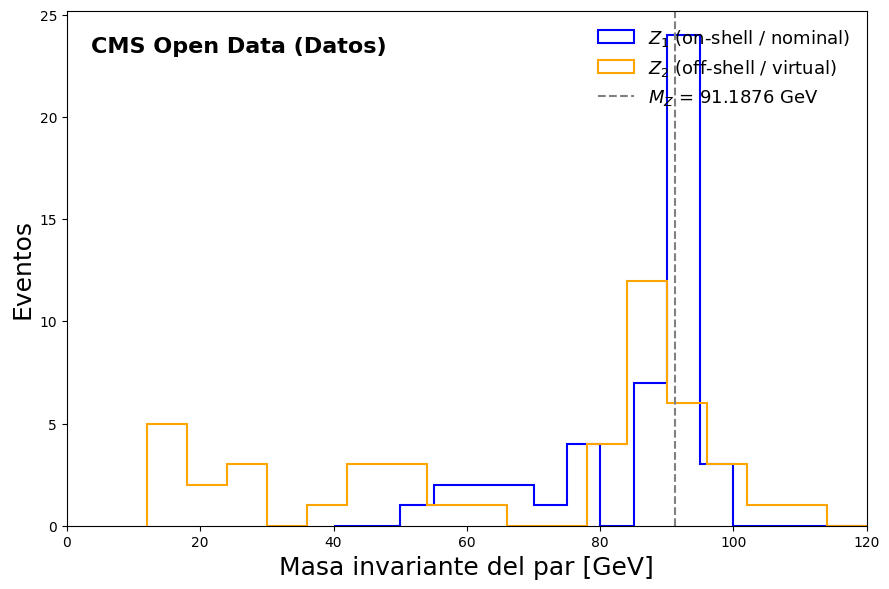

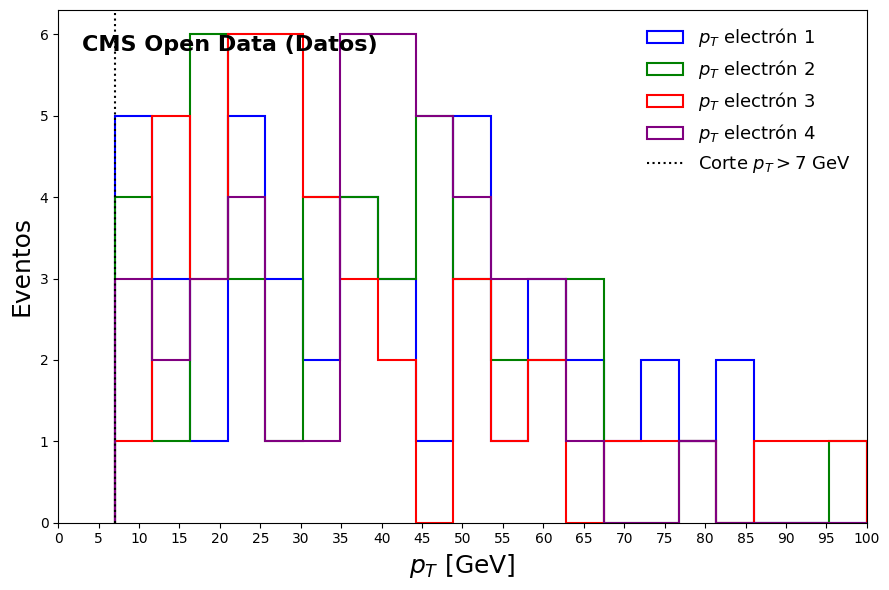

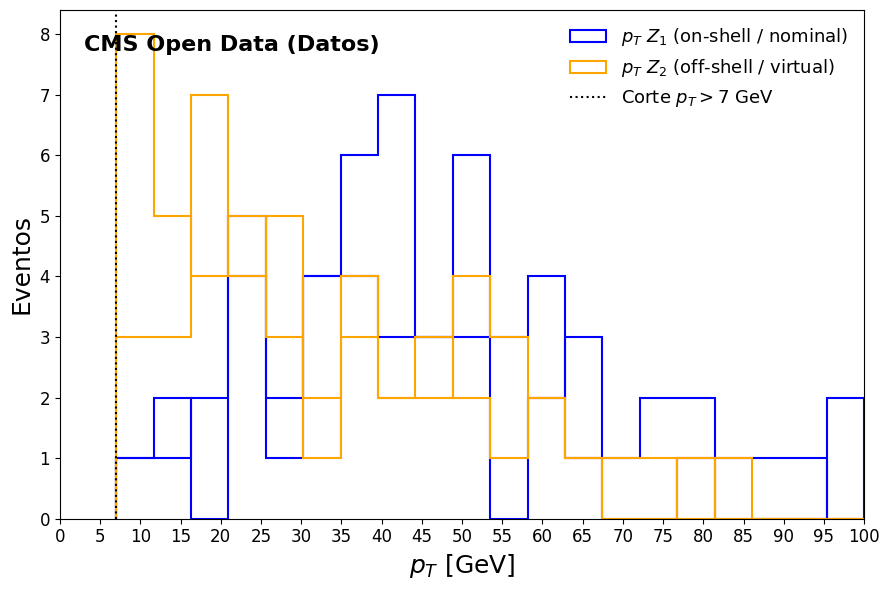

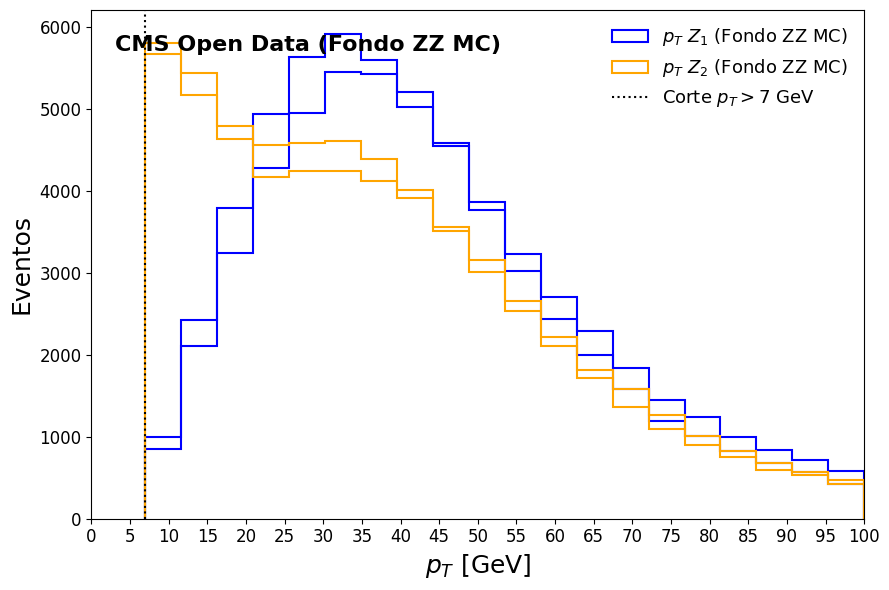

In [8]:
#  Gráfica: Masa invariante de los pares Z1 y Z2 (Datos Reales)
fig, ax = plt.subplots(figsize=(9, 6))

ax.hist(
    df_final_el["mZ1"],
    bins=16,
    range=(40, 120),
    histtype="step",
    color="blue",
    linewidth=1.5,
    label="$Z_1$ (on-shell / nominal)",
)
ax.hist(
    df_final_el["mZ2"],
    bins=18,
    range=(12, 120),
    histtype="step",
    color="orange",
    linewidth=1.5,
    label="$Z_2$ (off-shell / virtual)",
)
ax.axvline(
    Z_Mass_Nominal,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label=f"$M_Z$ = {Z_Mass_Nominal} GeV",
)

ax.set_xlabel("Masa invariante del par [GeV]", fontsize=18)
ax.set_ylabel("Eventos", fontsize=18)
ax.set_xlim(0, 120)

ax.text(
    0.03,
    0.92,
    "CMS Open Data (Datos)",
    transform=ax.transAxes,
    fontsize=16,
    fontweight="bold",
)
ax.legend(loc="upper right", frameon=False, fontsize=13)
plt.tight_layout()
plt.show()

# Gráfica: pT de los 4 electrones individuales (Datos Reales)
fig, ax = plt.subplots(figsize=(9, 6))
colores = ["blue", "green", "red", "purple"]
for i, color in zip(range(1, 5), colores):
    ax.hist(
        df_final_el[f"pt{i}"],
        bins=20,
        range=(7, 100),
        histtype="step",
        color=color,
        linewidth=1.5,
        label=f"$p_T$ electrón {i}",
    )

ax.axvline(7, color="black", linestyle=":", linewidth=1.5, label="Corte $p_T > 7$ GeV")
ax.set_xlabel("$p_T$ [GeV]", fontsize=18)
ax.set_ylabel("Eventos", fontsize=18) 
ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 5))
ax.text(
    0.03,
    0.92,
    "CMS Open Data (Datos)",
    transform=ax.transAxes,
    fontsize=16,
    fontweight="bold",
)
ax.legend(loc="upper right", frameon=False, fontsize=13)
plt.tight_layout()
plt.show()


# Extraer el pT de los electrones que forman Z1 y Z2 (Datos)
todos_indices = {1, 2, 3, 4}

pt_Z1_a = np.zeros(len(df_final_el))
pt_Z1_b = np.zeros(len(df_final_el))
for i in range(1, 5):
    mask_a = (df_final_el["Z1_idx_a"] == i)
    pt_Z1_a[mask_a] = df_final_el.loc[mask_a, f"pt{i}"]
    mask_b = (df_final_el["Z1_idx_b"] == i)
    pt_Z1_b[mask_b] = df_final_el.loc[mask_b, f"pt{i}"] 

df_final_el["pt_Z1a"] = pt_Z1_a
df_final_el["pt_Z1b"] = pt_Z1_b

pt_Z2_a = np.zeros(len(df_final_el))
pt_Z2_b = np.zeros(len(df_final_el))
idx_a_arr = df_final_el["Z1_idx_a"].astype(int).to_numpy()
idx_b_arr = df_final_el["Z1_idx_b"].astype(int).to_numpy()
pt_matrix = df_final_el[["pt1", "pt2", "pt3", "pt4"]].to_numpy()

for idx in range(len(df_final_el)):
    usados = {idx_a_arr[idx], idx_b_arr[idx]}
    restantes = sorted(todos_indices - usados)
    pt_Z2_a[idx] = pt_matrix[idx, restantes[0]-1]
    pt_Z2_b[idx] = pt_matrix[idx, restantes[1]-1]

df_final_el["pt_Z2a"] = pt_Z2_a
df_final_el["pt_Z2b"] = pt_Z2_b


# Gráfica: pT de los electrones de Z1 y Z2 (Datos)
fig, ax = plt.subplots(figsize=(9, 6))

ax.hist(
    df_final_el["pt_Z1a"], bins=20, range=(7, 100),
    histtype="step", color="blue", linewidth=1.5,
    label="$p_T$ $Z_1$ (on-shell / nominal)",
)
ax.hist(
    df_final_el["pt_Z1b"], bins=20, range=(7, 100),
    histtype="step", color="blue", linewidth=1.5,
)
ax.hist(
    df_final_el["pt_Z2a"], bins=20, range=(7, 100),
    histtype="step", color="orange", linewidth=1.5,
    label="$p_T$ $Z_2$ (off-shell / virtual)",
)
ax.hist(
    df_final_el["pt_Z2b"], bins=20, range=(7, 100),
    histtype="step", color="orange", linewidth=1.5,
)

ax.axvline(7, color="black", linestyle=":", linewidth=1.5, label="Corte $p_T > 7$ GeV")

ax.set_xlabel("$p_T$ [GeV]", fontsize=18)
ax.set_ylabel("Eventos", fontsize=18)
ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 5))

ax.tick_params(axis='both', labelsize=12)
ax.text(
    0.03,
    0.92,
    "CMS Open Data (Datos)",
    transform=ax.transAxes,
    fontsize=16,
    fontweight="bold",
)
ax.legend(loc="upper right", frameon=False, fontsize=13)
plt.tight_layout()
plt.show()


# Extraer el pT de los electrones para el Fondo ZZ MC (df_final_zz_el)
pt_Z1_a_zz = np.zeros(len(df_final_zz_el))
pt_Z1_b_zz = np.zeros(len(df_final_zz_el))
for i in range(1, 5):
    mask_a = (df_final_zz_el["Z1_idx_a"] == i)
    pt_Z1_a_zz[mask_a] = df_final_zz_el.loc[mask_a, f"pt{i}"]
    mask_b = (df_final_zz_el["Z1_idx_b"] == i)
    pt_Z1_b_zz[mask_b] = df_final_zz_el.loc[mask_b, f"pt{i}"] 

df_final_zz_el["pt_Z1a"] = pt_Z1_a_zz
df_final_zz_el["pt_Z1b"] = pt_Z1_b_zz

pt_Z2_a_zz = np.zeros(len(df_final_zz_el))
pt_Z2_b_zz = np.zeros(len(df_final_zz_el))
idx_a_arr_zz = df_final_zz_el["Z1_idx_a"].astype(int).to_numpy()
idx_b_arr_zz = df_final_zz_el["Z1_idx_b"].astype(int).to_numpy()
pt_matrix_zz = df_final_zz_el[["pt1", "pt2", "pt3", "pt4"]].to_numpy()

for idx in range(len(df_final_zz_el)):
    usados = {idx_a_arr_zz[idx], idx_b_arr_zz[idx]}
    restantes = sorted(todos_indices - usados)
    pt_Z2_a_zz[idx] = pt_matrix_zz[idx, restantes[0]-1]
    pt_Z2_b_zz[idx] = pt_matrix_zz[idx, restantes[1]-1]

df_final_zz_el["pt_Z2a"] = pt_Z2_a_zz
df_final_zz_el["pt_Z2b"] = pt_Z2_b_zz


# Gráfica: pT de los electrones de Z1 y Z2 para el Fondo ZZ MC
fig, ax = plt.subplots(figsize=(9, 6))

ax.hist(
    df_final_zz_el["pt_Z1a"], bins=20, range=(7, 100),
    histtype="step", color="blue", linewidth=1.5,
    label="$p_T$ $Z_1$ (Fondo ZZ MC)",
)
ax.hist(
    df_final_zz_el["pt_Z1b"], bins=20, range=(7, 100),
    histtype="step", color="blue", linewidth=1.5,
)
ax.hist(
    df_final_zz_el  ["pt_Z2a"], bins=20, range=(7, 100),
    histtype="step", color="orange", linewidth=1.5,
    label="$p_T$ $Z_2$ (Fondo ZZ MC)",
)
ax.hist(
    df_final_zz_el["pt_Z2b"], bins=20, range=(7, 100),
    histtype="step", color="orange", linewidth=1.5,
)

ax.axvline(7, color="black", linestyle=":", linewidth=1.5, label="Corte $p_T > 7$ GeV")

ax.set_xlabel("$p_T$ [GeV]", fontsize=18)
ax.set_ylabel("Eventos", fontsize=18)
ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 5))

ax.tick_params(axis='both', labelsize=12)
ax.text(
    0.03,
    0.92,
    "CMS Open Data (Fondo ZZ MC)",
    transform=ax.transAxes,
    fontsize=16,
    fontweight="bold",
)
ax.legend(loc="upper right", frameon=False, fontsize=13)
plt.tight_layout()
plt.show()

Datos reales filtrados: 46
Higgs filtrado:          6006
Fondo ZZ MC filtrado:   59246
Peso Higgs: 0.000248
Peso ZZ:    8.158494e-04


C:\Users\HP\AppData\Local\Temp\ipykernel_15004\1387004249.py:202: FutureWarning: kwarg `label` in function `label()` is deprecated and will be removed: Use `text="..."` instead.
  hep.cms.label(data=True, year="2012", com=8, label="Open Data", ax=ax


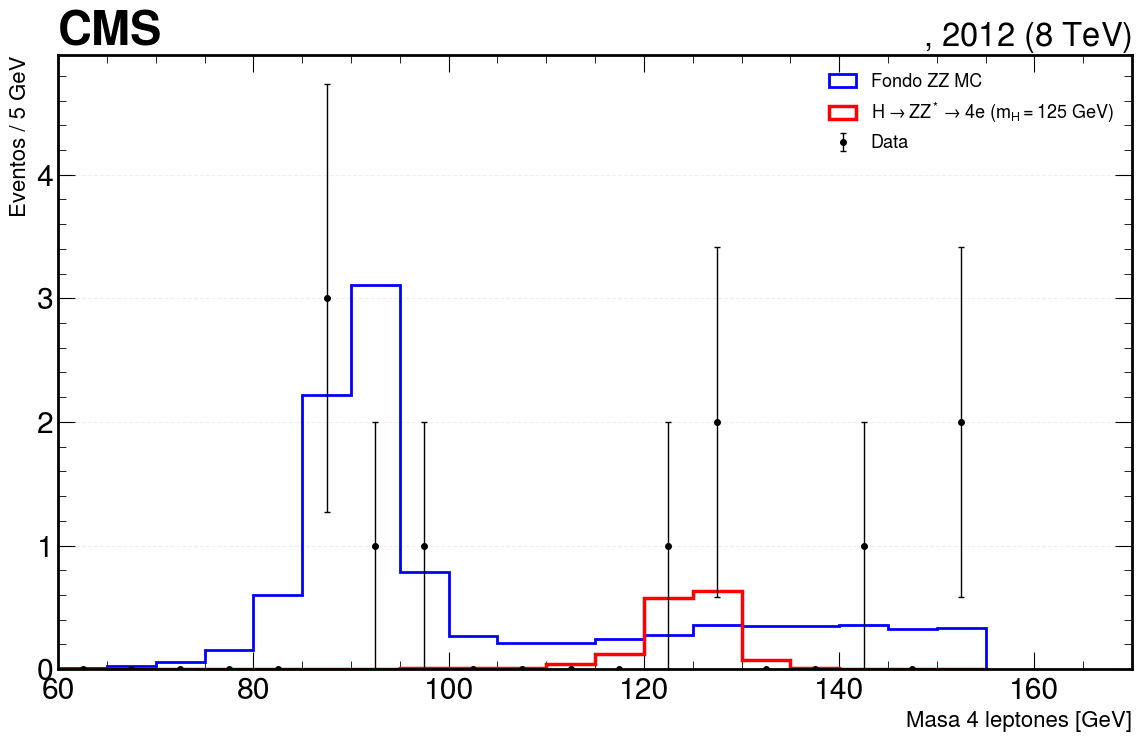

In [12]:
# Estilo CMS
hep.style.use("CMS")

# Parámetros Físicos para electrones
m_e = 0.000511  # Masa del electrón [GeV/c²]
Z_Mass_Nominal = 91.1876

# Función auxiliar para calcular Delta R (respetando periodicidad en phi)
def delta_r(eta1, phi1, eta2, phi2):
    d_eta = eta1 - eta2
    d_phi = np.arctan2(np.sin(phi1 - phi2), np.cos(phi1 - phi2))
    return np.sqrt(d_eta**2 + d_phi**2)

# Función para masa de un par de electrones
def masa_par(df, i, j):
    px = df[f"pt{i}"] * np.cos(df[f"phi{i}"]) + df[f"pt{j}"] * np.cos(df[f"phi{j}"])
    py = df[f"pt{i}"] * np.sin(df[f"phi{i}"]) + df[f"pt{j}"] * np.sin(df[f"phi{j}"])
    pz = df[f"pt{i}"] * np.sinh(df[f"eta{i}"]) + df[f"pt{j}"] * np.sinh(df[f"eta{j}"])
    E = np.sqrt(df[f"pt{i}"]**2 + df[f"pt{i}"]**2 * np.sinh(df[f"eta{i}"])**2 + m_e**2) + \
        np.sqrt(df[f"pt{j}"]**2 + df[f"pt{j}"]**2 * np.sinh(df[f"eta{j}"])**2 + m_e**2)
    return np.sqrt(np.maximum(0.0, E**2 - (px**2 + py**2 + pz**2)))

# Identificación de Z1 y Z2 con exigencia estricta de carga y Delta R > 0.02
def identificar_Z_onoff(df):
    pares = [((1, 2), (3, 4)), ((1, 3), (2, 4)), ((1, 4), (2, 3))]

    mejor_mZ1 = np.full(len(df), np.nan)
    mejor_mZ2 = np.full(len(df), np.nan)
    mejor_diff = np.full(len(df), np.inf)

    mejor_idx_a = np.zeros(len(df), dtype=int)
    mejor_idx_b = np.zeros(len(df), dtype=int)
    mejor_idx_c = np.zeros(len(df), dtype=int)
    mejor_idx_d = np.zeros(len(df), dtype=int)

    for (a, b), (c, d) in pares:
        carga_valida = (df[f"charge{a}"] + df[f"charge{b}"] == 0) & (
            df[f"charge{c}"] + df[f"charge{d}"] == 0
        )
        
        # Filtro angular Delta R para evitar solapamientos en ambos pares
        dr_ab = delta_r(df[f"eta{a}"], df[f"phi{a}"], df[f"eta{b}"], df[f"phi{b}"])
        dr_cd = delta_r(df[f"eta{c}"], df[f"phi{c}"], df[f"eta{d}"], df[f"phi{d}"])
        dr_valido = (dr_ab > 0.02) & (dr_cd > 0.02)

        valido = carga_valida & dr_valido

        m_ab, m_cd = masa_par(df, a, b), masa_par(df, c, d)

        ab_es_z1 = np.abs(m_ab - Z_Mass_Nominal) < np.abs(m_cd - Z_Mass_Nominal)
        m1 = np.where(ab_es_z1, m_ab, m_cd)
        m2 = np.where(ab_es_z1, m_cd, m_ab)
        idx_a = np.where(ab_es_z1, a, c)
        idx_b = np.where(ab_es_z1, b, d)
        idx_c = np.where(ab_es_z1, c, a)
        idx_d = np.where(ab_es_z1, d, b)

        diff = np.abs(m1 - Z_Mass_Nominal)
        mask = valido & (diff < mejor_diff)
        
        mejor_mZ1 = np.where(mask, m1, mejor_mZ1)
        mejor_mZ2 = np.where(mask, m2, mejor_mZ2)
        mejor_diff = np.where(mask, diff, mejor_diff)
        
        mejor_idx_a = np.where(mask, idx_a, mejor_idx_a)
        mejor_idx_b = np.where(mask, idx_b, mejor_idx_b)
        mejor_idx_c = np.where(mask, idx_c, mejor_idx_c)
        mejor_idx_d = np.where(mask, idx_d, mejor_idx_d)

    df["mZ1"], df["mZ2"] = mejor_mZ1, mejor_mZ2
    df["Z1_idx_a"], df["Z1_idx_b"] = mejor_idx_a, mejor_idx_b
    df["Z2_idx_c"], df["Z2_idx_d"] = mejor_idx_c, mejor_idx_d
    return df

# Reconstrucción del 4-vector del sistema de 4 electrones
def calcular_masa_electron(df):
    px = 0; py = 0; pz = 0; E = 0
    for i in range(1, 5):
        pxi = df[f"pt{i}"] * np.cos(df[f"phi{i}"])
        pyi = df[f"pt{i}"] * np.sin(df[f"phi{i}"])
        pzi = df[f"pt{i}"] * np.sinh(df[f"eta{i}"])
        Ei  = np.sqrt(pxi**2 + pyi**2 + pzi**2 + m_e**2)
        px += pxi; py += pyi; pz += pzi; E += Ei
        
    argumento_raiz = np.maximum(0, E**2 - (px**2 + py**2 + pz**2))
    return np.sqrt(argumento_raiz)


# Filtros y Masa para Datos Reales (df_4el)

for i in range(1, 5):
    ip3d_d = np.sqrt(df_4el[f"dxy{i}"] ** 2 + df_4el[f"dz{i}"] ** 2)
    sig_d = np.sqrt(df_4el[f"dxyErr{i}"] ** 2 + df_4el[f"dzErr{i}"] ** 2)
    df_4el[f"sip3d{i}"] = ip3d_d / sig_d

mask_pt_d = ((df_4el["pt1"] > 7) & (df_4el["pt2"] > 7) & (df_4el["pt3"] > 7) & (df_4el["pt4"] > 7))
mask_eta_d = ((df_4el["eta1"].abs() < 2.5) & (df_4el["eta2"].abs() < 2.5) & (df_4el["eta3"].abs() < 2.5) & (df_4el["eta4"].abs() < 2.5))
mask_iso_d = ((df_4el["iso1"] < 0.40) & (df_4el["iso2"] < 0.40) & (df_4el["iso3"] < 0.40) & (df_4el["iso4"] < 0.40))
mask_sip_d = ((df_4el["sip3d1"] < 4) & (df_4el["sip3d2"] < 4) & (df_4el["sip3d3"] < 4) & (df_4el["sip3d4"] < 4))
mask_dxy_data = ((df_4el["dxy1"].abs() < 0.5) & (df_4el["dxy2"].abs() < 0.5) & (df_4el["dxy3"].abs() < 0.5) & (df_4el["dxy4"].abs() < 0.5))
mask_dz_data = ((df_4el["dz1"].abs() < 1.0) & (df_4el["dz2"].abs() < 1.0) & (df_4el["dz3"].abs() < 1.0) & (df_4el["dz4"].abs() < 1.0))

df_data_f = df_4el[mask_pt_d & mask_eta_d & mask_iso_d & mask_sip_d & mask_dxy_data & mask_dz_data].copy()
df_data_f = identificar_Z_onoff(df_data_f)
df_data_f = df_data_f[(df_data_f["mZ1"] > 40) & (df_data_f["mZ1"] < 120) & (df_data_f["mZ2"] > 12) & (df_data_f["mZ2"] < 120)].copy()
df_data_f["M"] = calcular_masa_electron(df_data_f)

# Filtros y Masa para Higgs MC (df_4el_higgs)
for i in range(1, 5):
    ip3d_h = np.sqrt(df_4el_higgs[f"dxy{i}"] ** 2 + df_4el_higgs[f"dz{i}"] ** 2)
    sig_h = np.sqrt(df_4el_higgs[f"dxyErr{i}"] ** 2 + df_4el_higgs[f"dzErr{i}"] ** 2)
    df_4el_higgs[f"sip3d{i}"] = ip3d_h / sig_h

mask_pt_h = ((df_4el_higgs["pt1"] > 7) & (df_4el_higgs["pt2"] > 7) & (df_4el_higgs["pt3"] > 7) & (df_4el_higgs["pt4"] > 7))
mask_eta_h = ((df_4el_higgs["eta1"].abs() < 2.5) & (df_4el_higgs["eta2"].abs() < 2.5) & (df_4el_higgs["eta3"].abs() < 2.5) & (df_4el_higgs["eta4"].abs() < 2.5))
mask_iso_h = ((df_4el_higgs["iso1"] < 0.40) & (df_4el_higgs["iso2"] < 0.40) & (df_4el_higgs["iso3"] < 0.40) & (df_4el_higgs["iso4"] < 0.40))
mask_sip_h = ((df_4el_higgs["sip3d1"] < 4) & (df_4el_higgs["sip3d2"] < 4) & (df_4el_higgs["sip3d3"] < 4) & (df_4el_higgs["sip3d4"] < 4))
mask_dxy_h = ((df_4el_higgs["dxy1"].abs() < 0.5) & (df_4el_higgs["dxy2"].abs() < 0.5) & (df_4el_higgs["dxy3"].abs() < 0.5) & (df_4el_higgs["dxy4"].abs() < 0.5))
mask_dz_h = ((df_4el_higgs["dz1"].abs() < 1.0) & (df_4el_higgs["dz2"].abs() < 1.0) & (df_4el_higgs["dz3"].abs() < 1.0) & (df_4el_higgs["dz4"].abs() < 1.0))

df_higgs_f = df_4el_higgs[mask_pt_h & mask_eta_h & mask_iso_h & mask_sip_h & mask_dxy_h & mask_dz_h].copy()
df_higgs_f = identificar_Z_onoff(df_higgs_f)
df_higgs_f = df_higgs_f[(df_higgs_f["mZ1"] > 40) & (df_higgs_f["mZ1"] < 120) & (df_higgs_f["mZ2"] > 12) & (df_higgs_f["mZ2"] < 120)].copy()
df_higgs_f["M"] = calcular_masa_electron(df_higgs_f)


# Filtros y Masa para Fondo ZZ MC (df_4el_zz)
for i in range(1, 5):
    ip3d_zz = np.sqrt(df_4el_zz[f"dxy{i}"] ** 2 + df_4el_zz[f"dz{i}"] ** 2)
    sig_zz = np.sqrt(df_4el_zz[f"dxyErr{i}"] ** 2 + df_4el_zz[f"dzErr{i}"] ** 2)
    df_4el_zz[f"sip3d{i}"] = ip3d_zz / sig_zz

mask_pt_zz = ((df_4el_zz["pt1"] > 7) & (df_4el_zz["pt2"] > 7) & (df_4el_zz["pt3"] > 7) & (df_4el_zz["pt4"] > 7))
mask_eta_zz = ((df_4el_zz["eta1"].abs() < 2.5) & (df_4el_zz["eta2"].abs() < 2.5) & (df_4el_zz["eta3"].abs() < 2.5) & (df_4el_zz["eta4"].abs() < 2.5))
mask_iso_zz = ((df_4el_zz["iso1"] < 0.40) & (df_4el_zz["iso2"] < 0.40) & (df_4el_zz["iso3"] < 0.40) & (df_4el_zz["iso4"] < 0.40))
mask_sip_zz = ((df_4el_zz["sip3d1"] < 4) & (df_4el_zz["sip3d2"] < 4) & (df_4el_zz["sip3d3"] < 4) & (df_4el_zz["sip3d4"] < 4))
mask_dxy_zz = ((df_4el_zz["dxy1"].abs() < 0.5) & (df_4el_zz["dxy2"].abs() < 0.5) & (df_4el_zz["dxy3"].abs() < 0.5) & (df_4el_zz["dxy4"].abs() < 0.5))
mask_dz_zz = ((df_4el_zz["dz1"].abs() < 1.0) & (df_4el_zz["dz2"].abs() < 1.0) & (df_4el_zz["dz3"].abs() < 1.0) & (df_4el_zz["dz4"].abs() < 1.0))

df_zz_f = df_4el_zz[mask_pt_zz & mask_eta_zz & mask_iso_zz & mask_sip_zz & mask_dxy_zz & mask_dz_zz].copy()
df_zz_f = identificar_Z_onoff(df_zz_f)
df_zz_f = df_zz_f[(df_zz_f["mZ1"] > 40) & (df_zz_f["mZ1"] < 120) & (df_zz_f["mZ2"] > 12) & (df_zz_f["mZ2"] < 120)].copy()
df_zz_f["M"] = calcular_masa_electron(df_zz_f)

print("Datos reales filtrados:", len(df_data_f))
print("Higgs filtrado:         ", len(df_higgs_f))
print("Fondo ZZ MC filtrado:  ", len(df_zz_f))

# Pesos oficiales del CERN ajustados a tus archivos de 4 electrones
lumi = 11.46 * 1000
w_higgs = (0.0065 * lumi) / 299973.0
w_zz = (0.077 * 1.386 * lumi) / 1499093.0

print(f"Peso Higgs: {w_higgs:.6f}")
print(f"Peso ZZ:    {w_zz:.6e}")

# Gráfico unificado con Datos, Higgs y Fondo ZZ MC (Escala Lineal)
mis_bins = np.arange(60, 160, 5)

plt.figure(figsize=(12, 8))

# Fondo ZZ MC
plt.hist(
    df_zz_f["M"],
    bins=mis_bins,
    weights=np.full(len(df_zz_f), w_zz),
    label="Fondo ZZ MC",
    color="blue",
    histtype="step",
    linewidth=2,
)

# Señal de Higgs
plt.hist(
    df_higgs_f["M"],
    bins=mis_bins,
    weights=np.full(len(df_higgs_f), w_higgs),
    label=r"$H \to ZZ^* \to 4e$ ($m_H = 125$ GeV)",
    color="red",
    histtype="step",
    linewidth=2.5,
)

# Datos Reales
counts, bin_edges = np.histogram(df_data_f["M"], bins=mis_bins)
bin_centers = (bin_edges[1:] + bin_edges[:-1]) / 2
plt.errorbar(
    bin_centers,
    counts,
    yerr=np.sqrt(counts),
    fmt="o",
    color="black",
    markersize=4,
    capsize=2,
    elinewidth=1,
    linestyle="none",
    label="Data",
)

# Estética de la gráfica
ax = plt.gca()
hep.cms.label(data=True, year="2012", com=8, label="Open Data", ax=ax
)
plt.xlabel("Masa 4 leptones [GeV]", fontsize=16)
plt.ylabel("Eventos / 5 GeV", fontsize=16)
plt.xlim(60, 170)

plt.legend(loc="upper right", frameon=False, fontsize=13)
plt.grid(axis="y", alpha=0.2, linestyle="--")
plt.tight_layout()
plt.show()

In [10]:
# Guardar los DataFrames filtrados del canal de electrones (4el)
df_data_f.to_parquet("df_data_4el.parquet")
df_higgs_f.to_parquet("df_higgs_4el.parquet")
df_zz_f.to_parquet("df_zz_4el.parquet")

print("¡DataFrames del canal de electrones guardados exitosamente como parquet!")

¡DataFrames del canal de electrones guardados exitosamente como parquet!


In [16]:
# Filtrar eventos de Higgs que caen en la ventana del pico (120 a 130 GeV)
mask_pico_higgs = (df_higgs_f["M"] >= 120) & (df_higgs_f["M"] <= 130)
higgs_en_pico = df_higgs_f[mask_pico_higgs]

print(f"Eventos de Higgs totales: {len(df_higgs_f)}")
print(f"Eventos de Higgs dentro del pico (120-130 GeV): {len(higgs_en_pico)}")

# Ver una lista de los valores de masa exacta reconstruida (M)
print("\nPrimeros valores de masa del Higgs en el pico [GeV]:")
print(higgs_en_pico["M"].head(15).values)

# Ver el promedio y la mediana de toda la distribución del Higgs
print("\nEstadísticas de la masa reconstruida del Higgs:")
print(f"Masa promedio: {df_higgs_f['M'].mean():.2f} GeV")
print(f"Mediana: {df_higgs_f['M'].median():.2f} GeV")

Eventos de Higgs totales: 6006
Eventos de Higgs dentro del pico (120-130 GeV): 4883

Primeros valores de masa del Higgs en el pico [GeV]:
[123.17181  122.86316  123.00238  123.920296 128.66931  128.91986
 127.90979  123.44176  121.92916  122.26609  124.316696 129.3183
 125.34263  127.24284  124.964836]

Estadísticas de la masa reconstruida del Higgs:
Masa promedio: 124.06 GeV
Mediana: 124.88 GeV
